# Loan Prediction — od EDA do klasyfikacji
Python, pandas, scikit-learn. Dane: [Kaggle](https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset/data), plik `train_u6lujuX_CVtuZ9i.csv` (umieść obok notebooka). Cel: przewidzieć historyczną decyzję kredytową (Y=1, N=0), nie ryzyko niespłacenia kredytu. Główna metryka: F1 dla klasy Y. Przykład edukacyjny.
## 1. Import bibliotek
W razie potrzeby: `%pip install pandas numpy matplotlib scikit-learn`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
RANDOM_STATE = 42
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.3f}'.format)
print('pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)

pandas: 2.2.3 | scikit-learn: 1.8.0


## 2. Wczytanie i audyt jakości danych
Sprawdzamy wymiary, typy, duplikaty, braki i etykiety. Audyt techniczny dotyczy całego pliku; analizy zależności wykonamy na train.

In [2]:
df = pd.read_csv('train_u6lujuX_CVtuZ9i.csv')
print('Wymiary:', df.shape)
display(df.head())
df.info()

Wymiary: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.000,NaN,360.000,1.000,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.000,128.000,360.000,1.000,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.000,66.000,360.000,1.000,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.000,120.000,360.000,1.000,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.000,141.000,360.000,1.000,Urban,Y


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [3]:
print('Duplikaty wierszy:', df.duplicated().sum())
print('Powtórzone Loan_ID:', df['Loan_ID'].duplicated().sum())
missing = pd.DataFrame({'liczba': df.isna().sum(), 'procent': df.isna().mean()*100})
display(missing.sort_values('liczba', ascending=False))
display(pd.DataFrame({'liczba':df.Loan_Status.value_counts(), 'procent':df.Loan_Status.value_counts(normalize=True)*100}))
assert set(df.Loan_Status.unique()) == {'Y','N'}
assert df.Loan_ID.is_unique

Duplikaty wierszy: 0
Powtórzone Loan_ID: 0


,liczba,procent
Credit_History,50,8.143
Self_Employed,32,5.212
LoanAmount,22,3.583
Dependents,15,2.443
Loan_Amount_Term,14,2.280
Gender,13,2.117
Married,3,0.489
Education,0,0.000
Loan_ID,0,0.000
CoapplicantIncome,0,0.000


,liczba,procent
Loan_Status,,
Y,422,68.730
N,192,31.270


### Słownik zmiennych
| Kolumna | Znaczenie |
|---|---|
| Loan_ID | identyfikator |
| Gender | płeć |
| Married | stan cywilny |
| Dependents | liczba osób na utrzymaniu, także 3+ |
| Education | wykształcenie |
| Self_Employed | samozatrudnienie |
| ApplicantIncome | dochód wnioskodawcy |
| CoapplicantIncome | dochód współwnioskodawcy |
| LoanAmount | kwota kredytu |
| Loan_Amount_Term | okres kredytowania |
| Credit_History | binarna historia kredytowa |
| Property_Area | rodzaj obszaru nieruchomości |
| Loan_Status | decyzja Y/N |

Nie zakładamy konkretnej waluty bez zweryfikowanego słownika źródłowego.
## 3. Podział train/test
Odkładamy 20% danych. `stratify=y` zachowuje proporcje klas. Test nie służy do dopasowania preprocessing ani wyboru hiperparametrów.

In [4]:
X = df.drop(columns=['Loan_ID','Loan_Status'])
y = df.Loan_Status.map({'N':0,'Y':1})
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=.2,stratify=y,random_state=RANDOM_STATE)
train = X_train.assign(Loan_Status=y_train)
print('Train:', X_train.shape, '| Test:', X_test.shape)
display(pd.DataFrame({'train':y_train.value_counts(normalize=True), 'test':y_test.value_counts(normalize=True)}))

Train: (491, 11) | Test: (123, 11)


,train,test
Loan_Status,,
1,0.686,0.691
0,0.314,0.309


## 4. EDA na zbiorze treningowym
### 4.1. Rozkład klas i braki danych

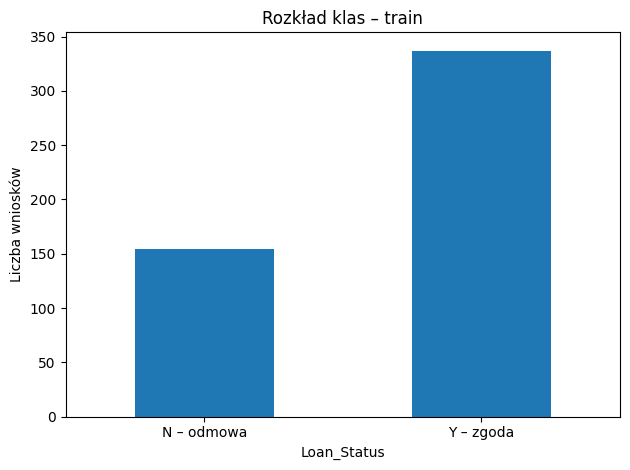

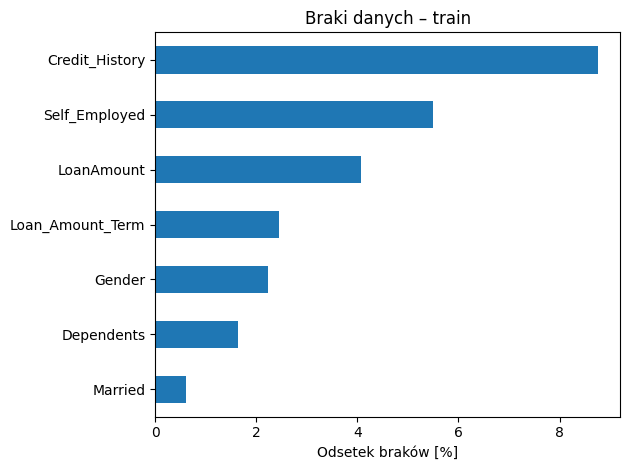

In [5]:
ax = y_train.value_counts().sort_index().rename(index={0:'N – odmowa',1:'Y – zgoda'}).plot.bar(rot=0)
ax.set(title='Rozkład klas – train', ylabel='Liczba wniosków'); plt.tight_layout(); plt.show()
ax = (X_train.isna().mean()*100).loc[lambda s:s>0].sort_values().plot.barh()
ax.set(title='Braki danych – train', xlabel='Odsetek braków [%]'); plt.tight_layout(); plt.show()

### 4.2. Zmienne ilościowe
Porównujemy statystyki opisowe, histogramy i rozkłady według decyzji. Historia kredytowa jest zmienną binarną, nie ciągłą.

,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,491.000,5529.998,6457.784,210.000,2906.000,3859.000,5825.000,81000.000
CoapplicantIncome,491.000,1569.537,2789.523,0.000,0.000,1032.000,2241.000,41667.000
LoanAmount,471.000,147.310,87.097,9.000,100.000,128.000,168.000,700.000
Loan_Amount_Term,479.000,341.286,65.855,12.000,360.000,360.000,360.000,480.000


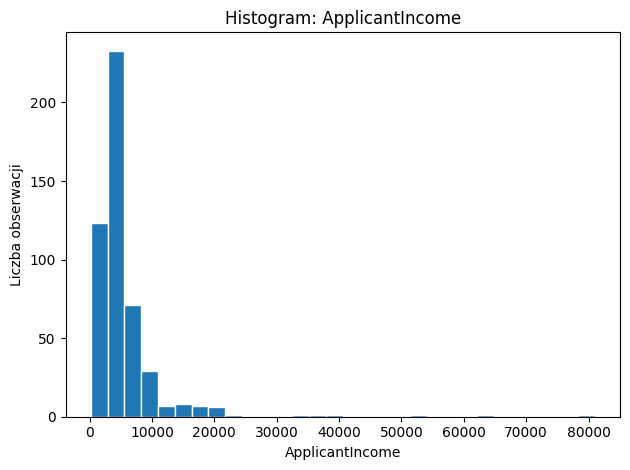

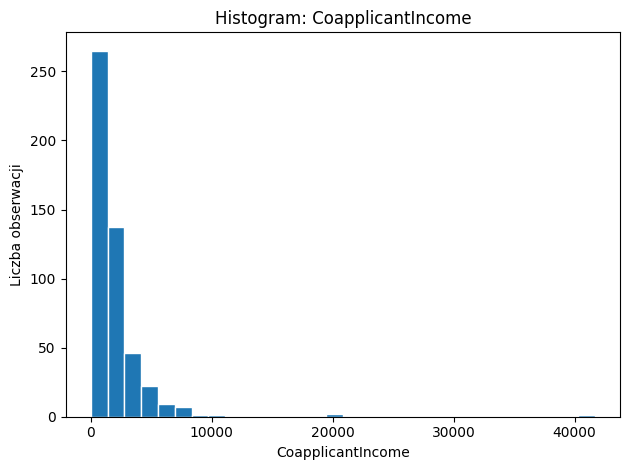

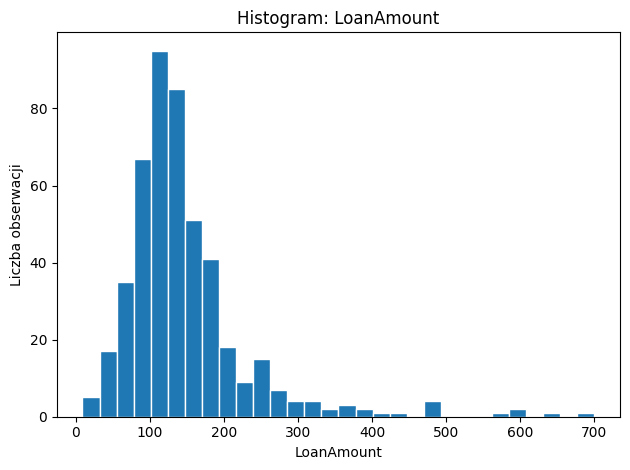

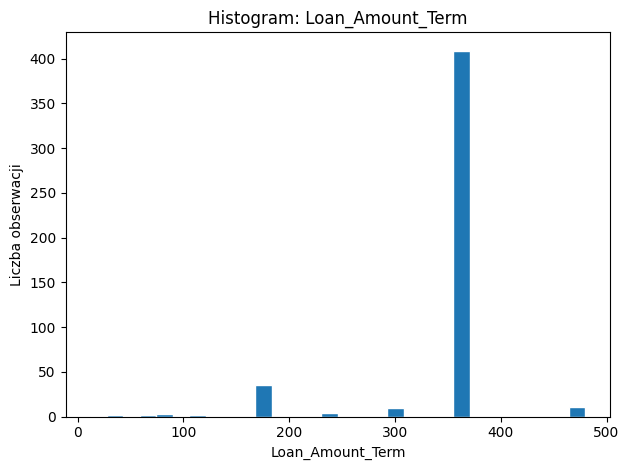

In [6]:
num_cols = ['ApplicantIncome','CoapplicantIncome','LoanAmount','Loan_Amount_Term']
cat_cols = ['Gender','Married','Dependents','Education','Self_Employed','Property_Area','Credit_History']
display(train[num_cols].describe().T)
for col in num_cols:
    ax = train[col].plot.hist(bins=30,edgecolor='white')
    ax.set(title=f'Histogram: {col}',xlabel=col,ylabel='Liczba obserwacji'); plt.tight_layout(); plt.show()

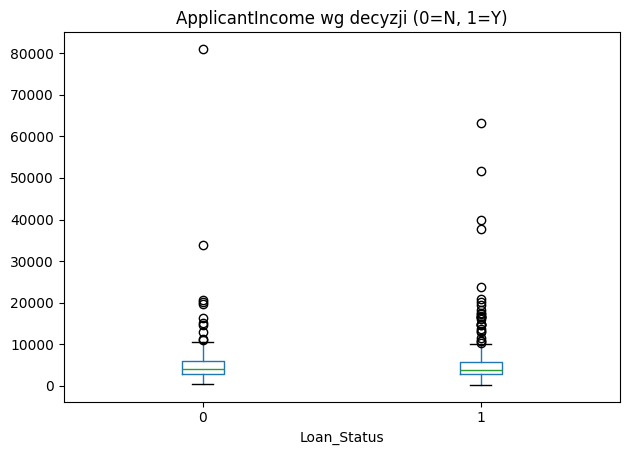

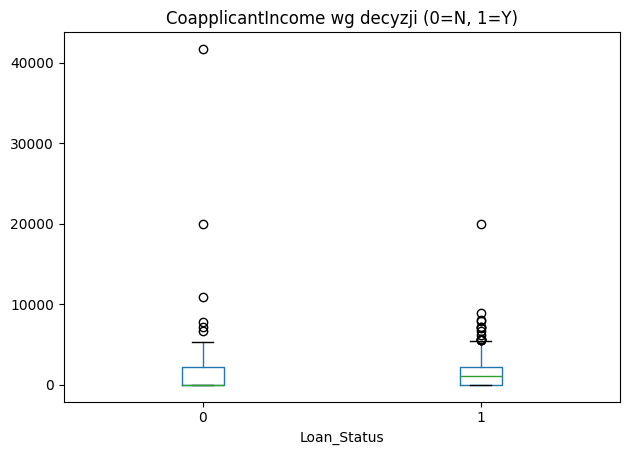

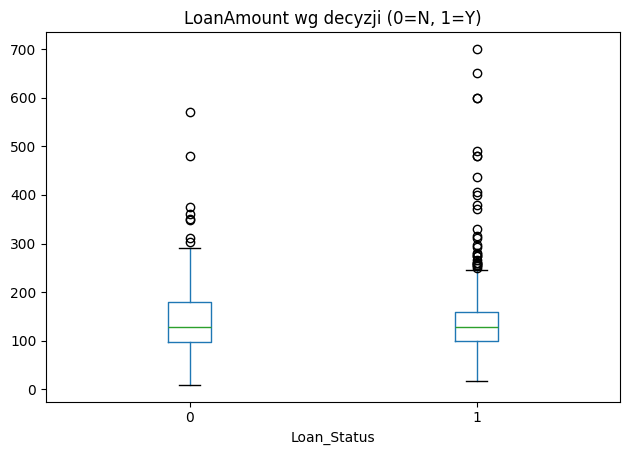

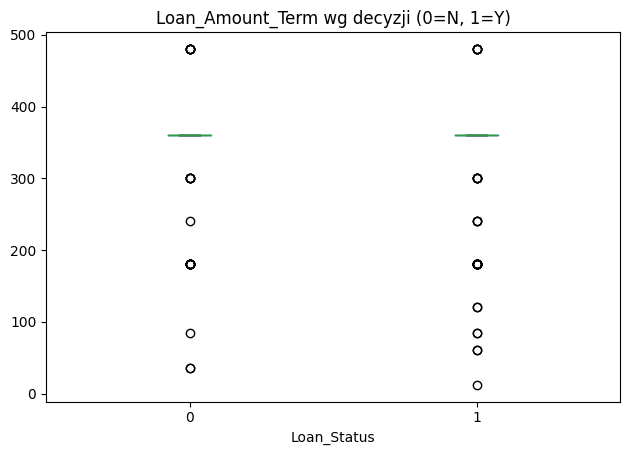

ApplicantIncome      40
CoapplicantIncome    21
LoanAmount           31
Loan_Amount_Term     70
Name: Liczba poza 1,5 IQR, dtype: int64

In [7]:
for col in num_cols:
    train.boxplot(column=col,by='Loan_Status',grid=False)
    plt.suptitle(''); plt.title(f'{col} wg decyzji (0=N, 1=Y)'); plt.tight_layout(); plt.show()
q1,q3 = train[num_cols].quantile(.25),train[num_cols].quantile(.75)
iqr = q3-q1
display(((train[num_cols]<q1-1.5*iqr)|(train[num_cols]>q3+1.5*iqr)).sum().rename('Liczba poza 1,5 IQR'))

Dochody i kwota kredytu mają prawostronną asymetrię. Wysoki dochód może być prawdziwy, więc nie usuwamy obserwacji wyłącznie na podstawie IQR. Transformacja logarytmiczna jest możliwym rozszerzeniem.
### 4.3. Zmienne kategorialne
Dla każdej kategorii liczymy liczebność i odsetek zgód. Braki pokazujemy osobno na potrzeby EDA.

Gender


,liczba,odsetek_Y
Gender,,
(brak),11,63.636
Female,87,70.115
Male,393,68.448


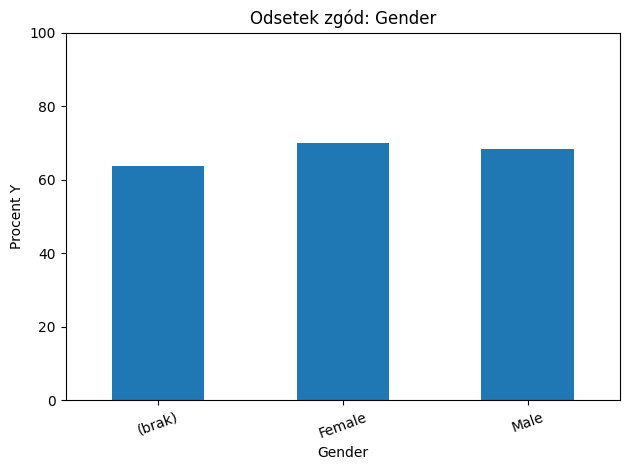

Married


,liczba,odsetek_Y
Married,,
(brak),3,100.000
No,169,64.497
Yes,319,70.533


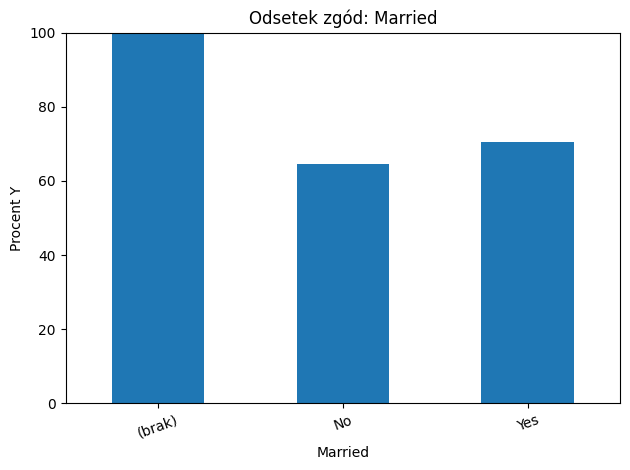

Dependents


,liczba,odsetek_Y
Dependents,,
(brak),8,75.000
0,276,67.754
1,85,65.882
2,83,74.699
3+,39,66.667


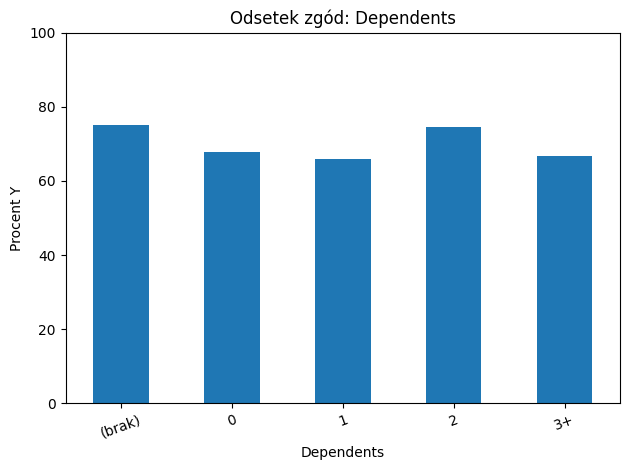

Education


,liczba,odsetek_Y
Education,,
Graduate,380,70.789
Not Graduate,111,61.261


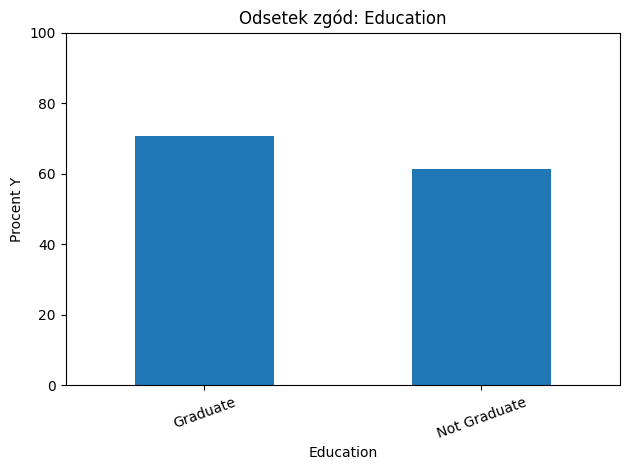

Self_Employed


,liczba,odsetek_Y
Self_Employed,,
(brak),27,70.370
No,398,68.844
Yes,66,66.667


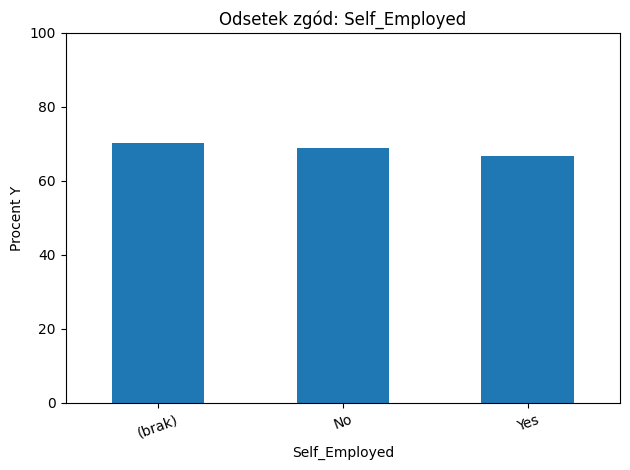

Property_Area


,liczba,odsetek_Y
Property_Area,,
Rural,145,60.690
Semiurban,184,77.717
Urban,162,65.432


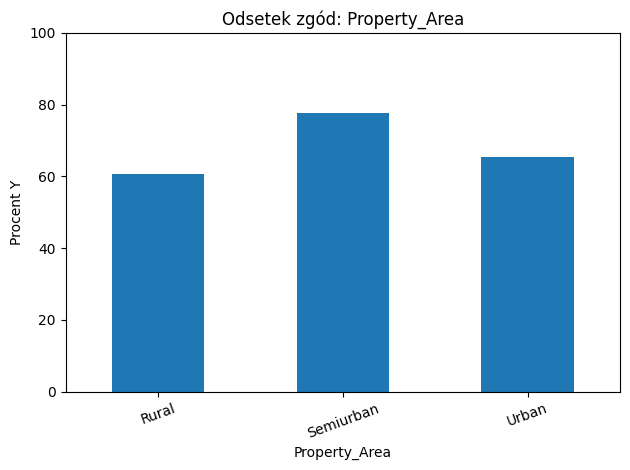

Credit_History


,liczba,odsetek_Y
Credit_History,,
(brak),43,69.767
0.0,67,8.955
1.0,381,79.003


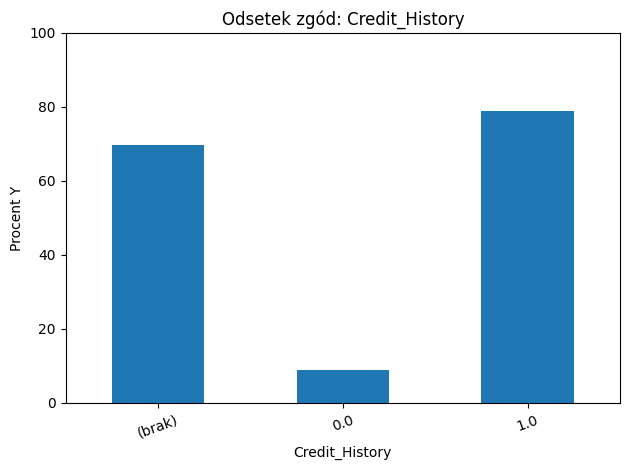

In [8]:
for col in cat_cols:
    group = train[col].astype('string').fillna('(brak)')
    tab = train.groupby(group).Loan_Status.agg(liczba='size',odsetek_Y='mean')
    tab['odsetek_Y'] *= 100
    print(col); display(tab)
    ax = tab.odsetek_Y.plot.bar(rot=20)
    ax.set(title=f'Odsetek zgód: {col}',ylabel='Procent Y',ylim=(0,100)); plt.tight_layout(); plt.show()

### 4.4. Korelacje
Korelacja Pearsona mierzy zależność liniową, nie przyczynowość.

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status
ApplicantIncome,1.000,-0.130,0.603,-0.045,-0.045,-0.016
CoapplicantIncome,-0.130,1.000,0.215,-0.101,-0.006,-0.047
LoanAmount,0.603,0.215,1.000,0.026,0.000,-0.007
Loan_Amount_Term,-0.045,-0.101,0.026,1.000,0.056,0.026
Credit_History,-0.045,-0.006,0.000,0.056,1.000,0.538
Loan_Status,-0.016,-0.047,-0.007,0.026,0.538,1.000


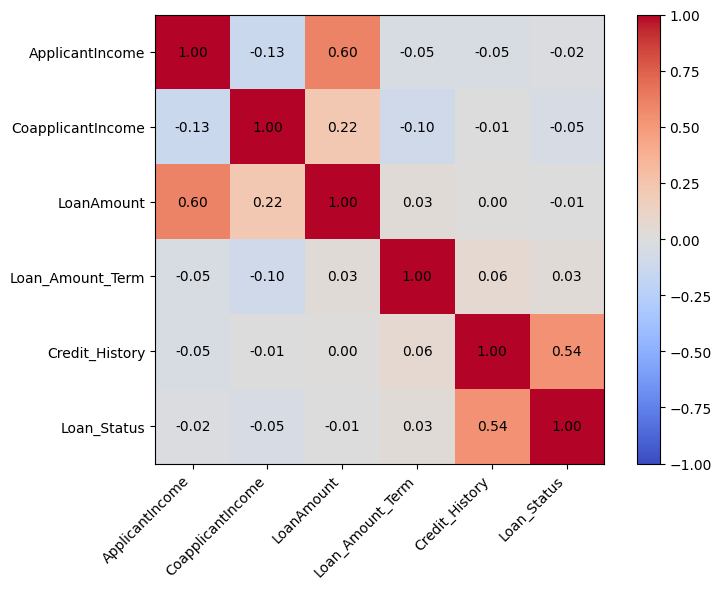

In [9]:
corr = train[num_cols+['Credit_History','Loan_Status']].corr()
display(corr)
fig,ax = plt.subplots(figsize=(8,6))
im = ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(corr)),corr.columns,rotation=45,ha='right')
ax.set_yticks(range(len(corr)),corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center')
fig.colorbar(im,ax=ax); plt.tight_layout(); plt.show()

## 5. Preprocessing
Usuwamy identyfikator. Dane ilościowe imputujemy medianą, kategorialne dominantą, następnie One-Hot Encoding. Dla regresji logistycznej skalujemy dane ilościowe. Drzewa nie wymagają skalowania. `Pipeline` dopasowuje preprocessing oddzielnie w każdym foldzie CV, zapobiegając przeciekowi danych.

In [10]:
def make_preprocessor(scale=False):
    num_steps = [('imputer',SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scaler',StandardScaler()))
    categorical = Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                            ('onehot',OneHotEncoder(handle_unknown='ignore'))])
    return ColumnTransformer([('num',Pipeline(num_steps),num_cols),('cat',categorical,cat_cols)])
make_preprocessor(scale=True)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

## 6. Metryka F1
$F1=2\frac{Precision\cdot Recall}{Precision+Recall}$, gdzie Precision = TP/(TP+FP), Recall = TP/(TP+FN).

Klasa pozytywna to zgoda (Y). F1 nie uwzględnia bezpośrednio TN, dlatego dodatkowo analizujemy F1 dla odmów i F1 macro. DummyClassifier przewidujący zawsze zgodę może mieć wysokie F1, mimo że nie wykrywa odmów.
## 7. Modele i GridSearchCV
5 stratyfikowanych foldów, wspólne dla wszystkich modeli. Wybieramy hiperparametry według F1 CV. Po strojeniu wyniki CV mogą być optymistyczne, dlatego mamy osobny test. Próg klasyfikacji pozostaje domyślny.

In [11]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
models = {
    'Regresja logistyczna': (LogisticRegression(max_iter=2000,random_state=RANDOM_STATE),True,
                            {'model__C':[.01,.1,1,10],'model__class_weight':[None,'balanced']}),
    'Drzewo decyzyjne': (DecisionTreeClassifier(random_state=RANDOM_STATE),False,
                         {'model__max_depth':[1,2,3,5,None],'model__min_samples_leaf':[1,5,10],
                          'model__class_weight':[None,'balanced']}),
    'Las losowy': (RandomForestClassifier(random_state=RANDOM_STATE,n_jobs=1),False,
                   {'model__n_estimators':[100],'model__max_depth':[3,5,None],
                    'model__min_samples_leaf':[1,5,10],'model__class_weight':[None,'balanced']})
}
baseline = Pipeline([('preprocessor',make_preprocessor()),('model',DummyClassifier(strategy='most_frequent'))])
baseline_cv = cross_val_score(baseline,X_train,y_train,cv=cv,scoring='f1')
baseline.fit(X_train,y_train)
searches = {}
rows = [{'Model':'Dummy','F1 CV':baseline_cv.mean(),'SD CV':baseline_cv.std()}]
for name,(estimator,scale,grid) in models.items():
    pipe = Pipeline([('preprocessor',make_preprocessor(scale)),('model',estimator)])
    search = GridSearchCV(pipe,grid,scoring='f1',cv=cv,n_jobs=1,refit=True,error_score='raise')
    search.fit(X_train,y_train)
    searches[name] = search
    rows.append({'Model':name,'F1 CV':search.best_score_,'SD CV':search.cv_results_['std_test_score'][search.best_index_]})
    print(name,':',search.best_params_)
cv_results = pd.DataFrame(rows).set_index('Model').sort_values('F1 CV',ascending=False)
display(cv_results)
best_name = max(searches,key=lambda name:searches[name].best_score_)
print('Model wybrany na podstawie CV:',best_name)

Regresja logistyczna : {'model__C': 0.1, 'model__class_weight': None}


Drzewo decyzyjne : {'model__class_weight': None, 'model__max_depth': 1, 'model__min_samples_leaf': 1}


Las losowy : {'model__class_weight': None, 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}


,F1 CV,SD CV
Model,,
Regresja logistyczna,0.871,0.027
Drzewo decyzyjne,0.870,0.027
Las losowy,0.870,0.027
Dummy,0.814,0.003


Model wybrany na podstawie CV: Regresja logistyczna


## 8. Ocena na zbiorze testowym
Wyniki wszystkich modeli pokazujemy informacyjnie, nie zmieniamy wyboru dokonanego na CV. F1 macro to średnia F1 obu klas.

,F1 CV,SD CV,F1 test (Y),Precision (Y),Recall (Y),F1 test (N),F1 macro,Accuracy
Model,,,,,,,,
Regresja logistyczna,0.871,0.027,0.908,0.840,0.988,0.721,0.815,0.862
Drzewo decyzyjne,0.870,0.027,0.903,0.832,0.988,0.700,0.802,0.854
Las losowy,0.870,0.027,0.903,0.832,0.988,0.700,0.802,0.854
Dummy,0.814,0.003,0.817,0.691,1.000,0.000,0.409,0.691


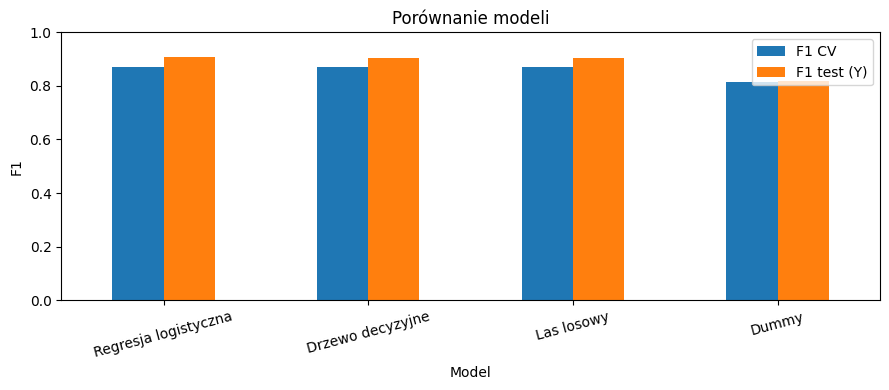

In [12]:
fitted = {'Dummy':baseline,**{name:s.best_estimator_ for name,s in searches.items()}}
results = []
for name,model in fitted.items():
    pred = model.predict(X_test)
    results.append({'Model':name,'F1 test (Y)':f1_score(y_test,pred,zero_division=0),
                    'Precision (Y)':precision_score(y_test,pred,zero_division=0),
                    'Recall (Y)':recall_score(y_test,pred,zero_division=0),
                    'F1 test (N)':f1_score(y_test,pred,pos_label=0,zero_division=0),
                    'F1 macro':f1_score(y_test,pred,average='macro',zero_division=0),
                    'Accuracy':accuracy_score(y_test,pred)})
results = cv_results.join(pd.DataFrame(results).set_index('Model'))
display(results)
ax = results[['F1 CV','F1 test (Y)']].plot.bar(rot=15,ylim=(0,1),figsize=(9,4))
ax.set(ylabel='F1',title='Porównanie modeli'); plt.tight_layout(); plt.show()

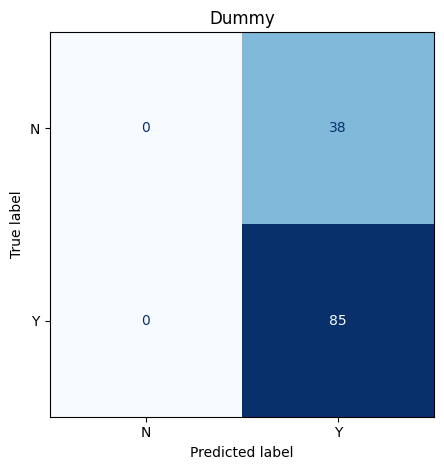

Dummy
              precision    recall  f1-score   support

  N – odmowa       0.00      0.00      0.00        38
   Y – zgoda       0.69      1.00      0.82        85

    accuracy                           0.69       123
   macro avg       0.35      0.50      0.41       123
weighted avg       0.48      0.69      0.56       123



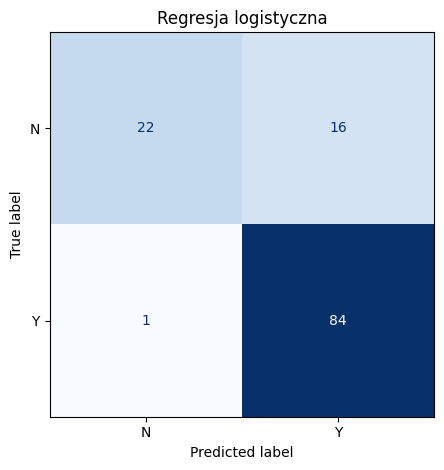

Regresja logistyczna
              precision    recall  f1-score   support

  N – odmowa       0.96      0.58      0.72        38
   Y – zgoda       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



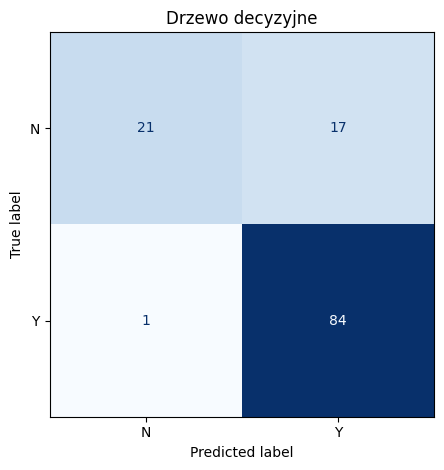

Drzewo decyzyjne
              precision    recall  f1-score   support

  N – odmowa       0.95      0.55      0.70        38
   Y – zgoda       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



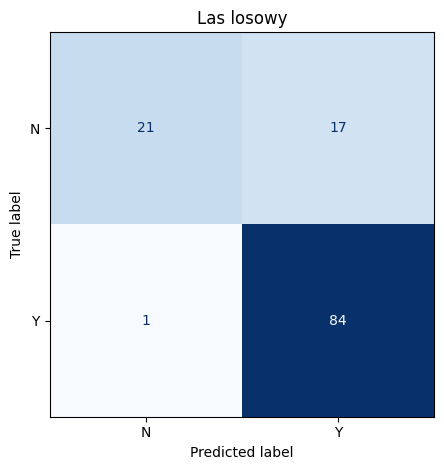

Las losowy
              precision    recall  f1-score   support

  N – odmowa       0.95      0.55      0.70        38
   Y – zgoda       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



In [13]:
for name,model in fitted.items():
    ConfusionMatrixDisplay.from_estimator(model,X_test,y_test,labels=[0,1],display_labels=['N','Y'],cmap='Blues',colorbar=False)
    plt.title(name); plt.tight_layout(); plt.show()
    print(name)
    print(classification_report(y_test,model.predict(X_test),labels=[0,1],target_names=['N – odmowa','Y – zgoda'],zero_division=0))

## 9. Interpretacja wybranego modelu
Permutation importance mierzy spadek F1 po przetasowaniu oryginalnej cechy. Obliczamy ją opisowo na teście, nie wykorzystujemy jej do ponownego wyboru cech. Nie jest to dowód przyczynowości.

,mean,std
Credit_History,0.151,0.023
CoapplicantIncome,0.007,0.004
Gender,0.000,0.000
Dependents,0.000,0.000
Married,0.000,0.000
Self_Employed,0.000,0.000
Education,0.000,0.000
ApplicantIncome,0.000,0.000
LoanAmount,0.000,0.000
Loan_Amount_Term,0.000,0.000


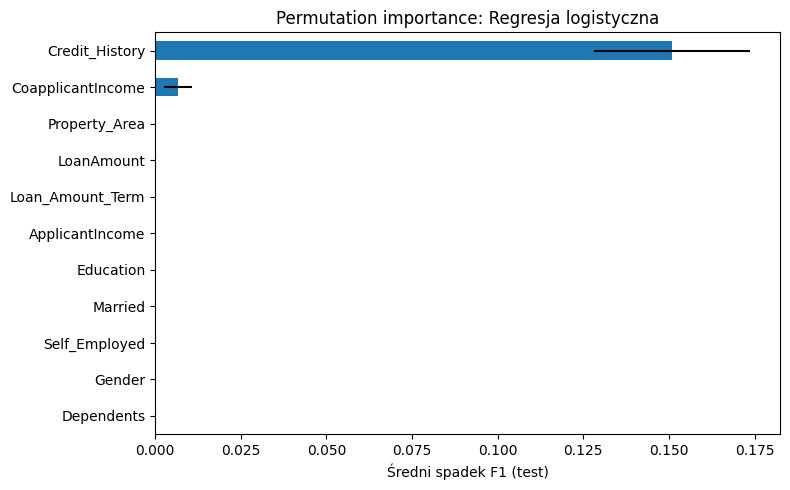

In [14]:
best_model = fitted[best_name]
perm = permutation_importance(best_model,X_test,y_test,scoring='f1',n_repeats=30,random_state=RANDOM_STATE,n_jobs=1)
importance = pd.DataFrame({'mean':perm.importances_mean,'std':perm.importances_std},index=X_test.columns).sort_values('mean',ascending=False)
display(importance)
ax = importance['mean'].sort_values().plot.barh(xerr=importance['std'],figsize=(8,5))
ax.set(title=f'Permutation importance: {best_name}',xlabel='Średni spadek F1 (test)'); plt.tight_layout(); plt.show()

## 10. Predykcja pojedynczej obserwacji
Przekazujemy surowy DataFrame. Pipeline sam wykonuje preprocessing.

In [15]:
example = X_test.iloc[[0]]
display(example)
print('Predykcja:',best_model.predict(example)[0])
print('P(Y=1) wg modelu:',round(best_model.predict_proba(example)[0,1],3))
print('Rzeczywista decyzja:',y_test.loc[example.index].iloc[0])

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
150,Male,No,0,Graduate,No,6277,0.000,118.000,360.000,0.000,Rural


Predykcja: 0
P(Y=1) wg modelu: 0.193
Rzeczywista decyzja: 0


## Podsumowanie uzyskanych wyników (random_state=42)
| Model | F1 CV | F1 test (Y) | F1 test (N) | F1 macro |
|---|---:|---:|---:|---:|
| Regresja logistyczna | 0,871 | 0,908 | 0,721 | 0,815 |
| Drzewo decyzyjne | 0,870 | 0,903 | 0,700 | 0,802 |
| Las losowy | 0,870 | 0,903 | 0,700 | 0,802 |
| Dummy | 0,814 | 0,817 | 0,000 | 0,409 |

- Wybór na podstawie CV: regresja logistyczna (C=0,1, bez ważenia klas). Różnica F1 CV jest minimalna w stosunku do odchylenia między foldami (0,027), więc nie dowodzi trwałej przewagi.
- Najlepsze drzewo ma głębokość 1: zależność od historii kredytowej jest silna (79,0% zgód przy Credit_History=1 wobec 9,0% przy 0 na train). Korelacja z etykietą: 0,538.
- Na teście regresja logistyczna daje TN=22, FP=16, FN=1, TP=84. Recall zgód 98,8%, lecz wykrywa tylko 22 z 38 odmów (57,9%).
- Permutation importance: Credit_History ma największe znaczenie; średni spadek F1 po przetasowaniu wynosi 0,151. Zerowe znaczenie innych cech w tej analizie nie wyklucza ich wpływu w innych próbach lub przy innych progach.
- Dummy zawsze przewiduje Y, więc mimo F1=0,817 nie wykrywa żadnej odmowy. W problemie z równorzędnymi klasami warto rozważyć F1 macro jako główną metrykę.

## 11. Ograniczenia i dalsze kroki
Dane są niewielkie; test ma 123 przypadki. Brak dat uniemożliwia walidację czasową. Płeć i stan cywilny mogą prowadzić do dyskryminacji; pozostawiono je wyłącznie w demonstracji edukacyjnej. Wdrożenie wymaga audytu sprawiedliwości, oceny zasadności i legalności cech, walidacji na niezależnych danych. Etykieta oznacza decyzję historyczną, nie ryzyko niespłacenia.

Rozszerzenia: usunięcie cech wrażliwych, optymalizacja progu na predykcjach out-of-fold (nie na teście), PR-AUC, powtarzana/zagnieżdżona CV, nowe cechy dochodowe oraz transformacje logarytmiczne sprawdzone w CV.